# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, chi2_contingency

### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- 

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
print("Edades con decimales:", (df["edad"] % 1 != 0).sum())

df["edad"] = df["edad"].astype(int)
df.info()

Edades con decimales: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ["edad", "nivel_ingreso", "visitas_mes", "compras_mes",
                      "gasto_publicidad_dirigida", "satisfaccion", "ingreso_anual"]

df[columnas_numericas].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


✍️ **Comentario**: ✍️ Diagnóstico inicial de variables numéricas

| Variable | Rango | Valor típico | Lo más relevante |
|---|---|---|---|
| 👤 `edad` | 18 – 75 | 38 años | Media y mediana casi iguales: distribución equilibrada, sin extremos preocupantes. |
| 💼 `nivel_ingreso` | 8,000 – 74,791 | ≈ 30,000 | Distribución centrada, aunque un pequeño grupo de clientes tiene ingresos muy por encima del resto. |
| 📱 `visitas_mes` | 1 – 25 | 10 visitas | La mitad visita entre 8 y 12 veces al mes; algunos usuarios muy activos llegan a 25. |
| 🛒 `compras_mes` | 0 – 8 | 1 compra | Actividad de compra baja: al menos el 25 % de los clientes no compró nada en el mes. |
| 📢 `gasto_publicidad_dirigida` | 0 – 75.51 | ≈ 20 | El máximo está muy lejos del 75 % (27.29): pocos usuarios concentran mucha inversión publicitaria. |
| ⭐ `satisfaccion` | 1 – 5 | 3.6 | Todo dentro del rango válido; satisfacción moderadamente positiva y con poca variación. |
| 💰 `ingreso_anual` | 0 – 244.69 | ≈ 30.7 | Al menos el 25 % no generó ingresos; media > mediana y máximo muy alejado: **fuerte sesgo a la derecha**. |

> **📌 Conclusión del diagnóstico**
>
> No se encontraron valores imposibles, negativos ni fuera de rango, por lo que no es necesario eliminar registros.
>
> Sin embargo, `ingreso_anual` y `gasto_publicidad_dirigida` presentan **sesgo y valores atípicos**. Por eso, en el análisis de correlación se compararán **Pearson y Spearman**, ya que Spearman es menos sensible a estos extremos.

#### Explorar variables binarias

In [8]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ["miembro_premium", "abandono"]

for col in columnas_binarias:
    print(f"📊 {col}")
    print("Valores únicos:", sorted(df[col].unique()))
    print(df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")
    print()

📊 miembro_premium
Valores únicos: [0, 1]
0    86.07 %
1    13.93 %
Name: miembro_premium, dtype: object

📊 abandono
Valores únicos: [0, 1]
0    84.93 %
1    15.07 %
Name: abandono, dtype: object



✍️ **Comentario**: ✍️ Diagnóstico inicial de variables binarias

| Variable | Valores | Distribución | Lo más relevante |
|---|---|---|---|
| 💎 `miembro_premium` | 0 / 1 | 86.07 % no · 13.93 % sí | Solo uno de cada siete clientes tiene suscripción premium (aprox. 2,090 clientes); es un grupo pequeño pero bien representado. |
| 🚪 `abandono` | 0 / 1 | 84.93 % no · 15.07 % sí | Aproximadamente uno de cada siete clientes abandonó la plataforma (cerca de 2,260 clientes), una proporción relevante para el equipo de retención. |

> **📌 Conclusión del diagnóstico**
>
> Ambas columnas contienen únicamente los valores 0 y 1, por lo que están correctamente codificadas y **no requieren transformación**.
>
> Las dos variables están **desbalanceadas**: el grupo con valor 1 representa menos del 16 % de los clientes. Aun así, cada grupo tiene más de 2,000 registros, suficiente para analizar su relación con `ingreso_anual` mediante la **correlación punto-biserial**.

#### Explorar variables categóricas

In [9]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ["id_cliente", "tipo_dispositivo", "region"]

print("🔢 Valores únicos por columna:")
print(df[columnas_categoricas].nunique())
print()

for col in ["tipo_dispositivo", "region"]:
    print(f"📊 {col}")
    print(df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")
    print()

🔢 Valores únicos por columna:
id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

📊 tipo_dispositivo
móvil         65.45 %
escritorio     24.8 %
tablet         9.75 %
Name: tipo_dispositivo, dtype: object

📊 region
norte     29.3 %
oeste     25.4 %
sur      24.84 %
este     20.46 %
Name: region, dtype: object



In [10]:
# Explorar variables categóricas y cómo se distribuyen
for col in ["tipo_dispositivo", "region"]:
    conteo = df[col].value_counts()
    porcentaje = df[col].value_counts(normalize=True).mul(100).round(2)
    print(f"📊 {col}")
    print(pd.DataFrame({"clientes": conteo, "porcentaje (%)": porcentaje}))
    print()

📊 tipo_dispositivo
            clientes  porcentaje (%)
móvil           9818           65.45
escritorio      3720           24.80
tablet          1462            9.75

📊 region
       clientes  porcentaje (%)
norte      4395           29.30
oeste      3810           25.40
sur        3726           24.84
este       3069           20.46



✍️ **Comentario**: ✍️ Diagnóstico inicial de variables categóricas

| Variable | Categorías | Distribución | Lo más relevante |
|---|---|---|---|
| 🆔 `id_cliente` | 15,000 únicos | 1 registro por cliente | Cada identificador aparece una sola vez: **no hay clientes duplicados**. Al ser solo un identificador, no se incluye en el análisis de correlación. |
| 📱 `tipo_dispositivo` | 3 | móvil 65.45 % · escritorio 24.80 % · tablet 9.75 % | El móvil domina claramente: casi dos de cada tres clientes lo usan como dispositivo principal, mientras que la tablet es minoritaria (1,462 clientes). |
| 🗺️ `region` | 4 | norte 29.30 % · oeste 25.40 % · sur 24.84 % · este 20.46 % | Los clientes están repartidos de forma bastante equilibrada; el norte concentra la mayor proporción y el este la menor. |

> **📌 Conclusión del diagnóstico**
>
> Las categorías coinciden exactamente con las esperadas (móvil, escritorio y tablet; norte, sur, oeste y este), sin variantes mal escritas ni valores inconsistentes, por lo que **no se requiere limpieza adicional**.
>
> El predominio del móvil será un punto a considerar al interpretar resultados, ya que cualquier patrón general del dataset estará fuertemente influido por el comportamiento de estos usuarios. La relación entre estas variables se analizará más adelante con la **V de Cramér**.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

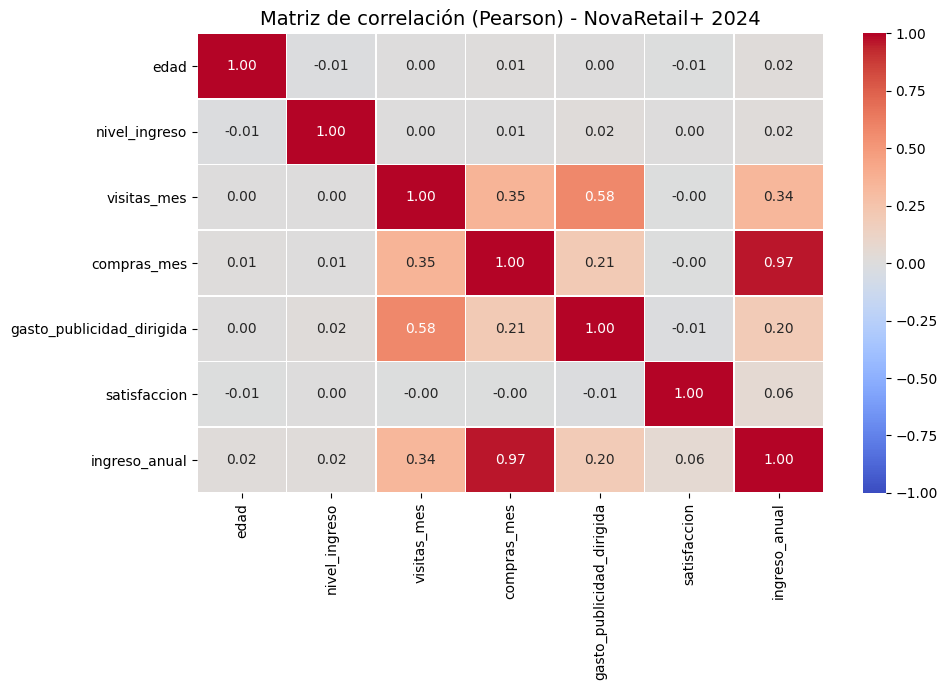

In [11]:
# Visualizar la matriz de correlación para identificar relaciones
columnas_numericas = ["edad", "nivel_ingreso", "visitas_mes", "compras_mes",
                      "gasto_publicidad_dirigida", "satisfaccion", "ingreso_anual"]

corr = df[columnas_numericas].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de correlación (Pearson) - NovaRetail+ 2024", fontsize=14)
plt.tight_layout()
plt.show()

✍️ **Comentario**: ✍️ Observaciones del Heatmap

**🔍 Observaciones generales**

- Se observa que **la mayoría de las variables son prácticamente independientes entre sí**: gran parte del mapa está en tonos grises, con correlaciones entre -0.01 y 0.02.
- **No aparece ninguna correlación negativa relevante**; todas las relaciones con algo de fuerza son positivas.
- Destaca un pequeño **bloque de comportamiento digital** formado por `visitas_mes`, `compras_mes` y `gasto_publicidad_dirigida`:
  - `visitas_mes` y `gasto_publicidad_dirigida` tienen una relación **moderada (0.58)**: los usuarios que más visitan la plataforma son también los que reciben más inversión publicitaria. No es posible saber, solo con estos datos, si la publicidad genera visitas o si simplemente se dirige a los usuarios más activos.
  - `visitas_mes` y `compras_mes` muestran una relación **débil-moderada (0.35)**: visitar más no se traduce necesariamente en comprar más.
- `edad`, `nivel_ingreso` y `satisfaccion` no se relacionan de forma lineal con ninguna otra variable.

**💰 Observaciones respecto a `ingreso_anual`**

| Variable | Correlación | Lectura |
|---|---|---|
| 🛒 `compras_mes` | **0.97** | Relación casi perfecta ⚠️ |
| 📱 `visitas_mes` | 0.34 | Débil-moderada |
| 📢 `gasto_publicidad_dirigida` | 0.20 | Débil |
| ⭐ `satisfaccion` | 0.06 | Prácticamente nula |
| 👤 `edad` | 0.02 | Nula |
| 💼 `nivel_ingreso` | 0.02 | Nula |

- Presenta una correlación **casi perfecta con `compras_mes` (0.97)**, lo que indica **colinealidad**: el ingreso anual es, en la práctica, un reflejo directo del número de compras. Es una relación esperable (más compras implican más ingreso), por lo que **no debe interpretarse como un hallazgo de negocio**, sino como dos medidas de lo mismo.
- La relación con `gasto_publicidad_dirigida` (0.20) es débil y podría ser **indirecta**: la publicidad se asocia con más visitas, y las visitas con más compras. Habrá que validarla con cuidado antes de sacar conclusiones.
- Llama la atención que **ni el ingreso personal del cliente (`nivel_ingreso`) ni su satisfacción** se asocian con lo que genera para la empresa: ganar más o estar más satisfecho no implica, por sí solo, aportar más ingresos.

> **📌 Conclusión:** el ingreso anual parece depender casi por completo de la **frecuencia de compra**, y en menor medida del nivel de actividad en la plataforma. Estos resultados se validarán en la siguiente sección con **Spearman**, ya que `ingreso_anual` presenta sesgo y valores atípicos.

### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:
  - Explica por qué.

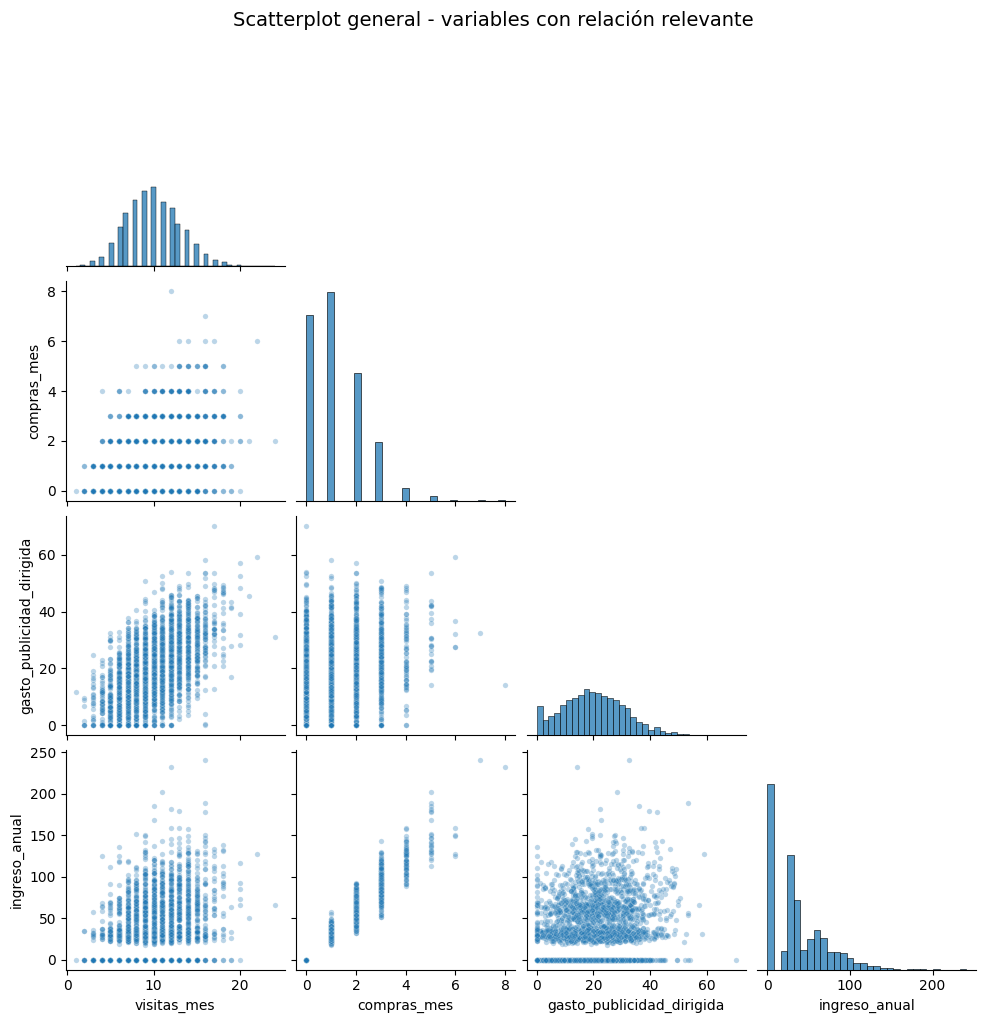

In [12]:
# Scatterplot general de las variables con relación relevante
columnas_relevantes = ["visitas_mes", "compras_mes", "gasto_publicidad_dirigida", "ingreso_anual"]

# muestra aleatoria para evitar saturación visual con 15,000 puntos
muestra = df[columnas_relevantes].sample(3000, random_state=42)

g = sns.pairplot(muestra, plot_kws={"alpha": 0.3, "s": 15}, corner=True)
g.fig.suptitle("Scatterplot general - variables con relación relevante", y=1.02, fontsize=14)
plt.show()

### Scatterplot para pares clave

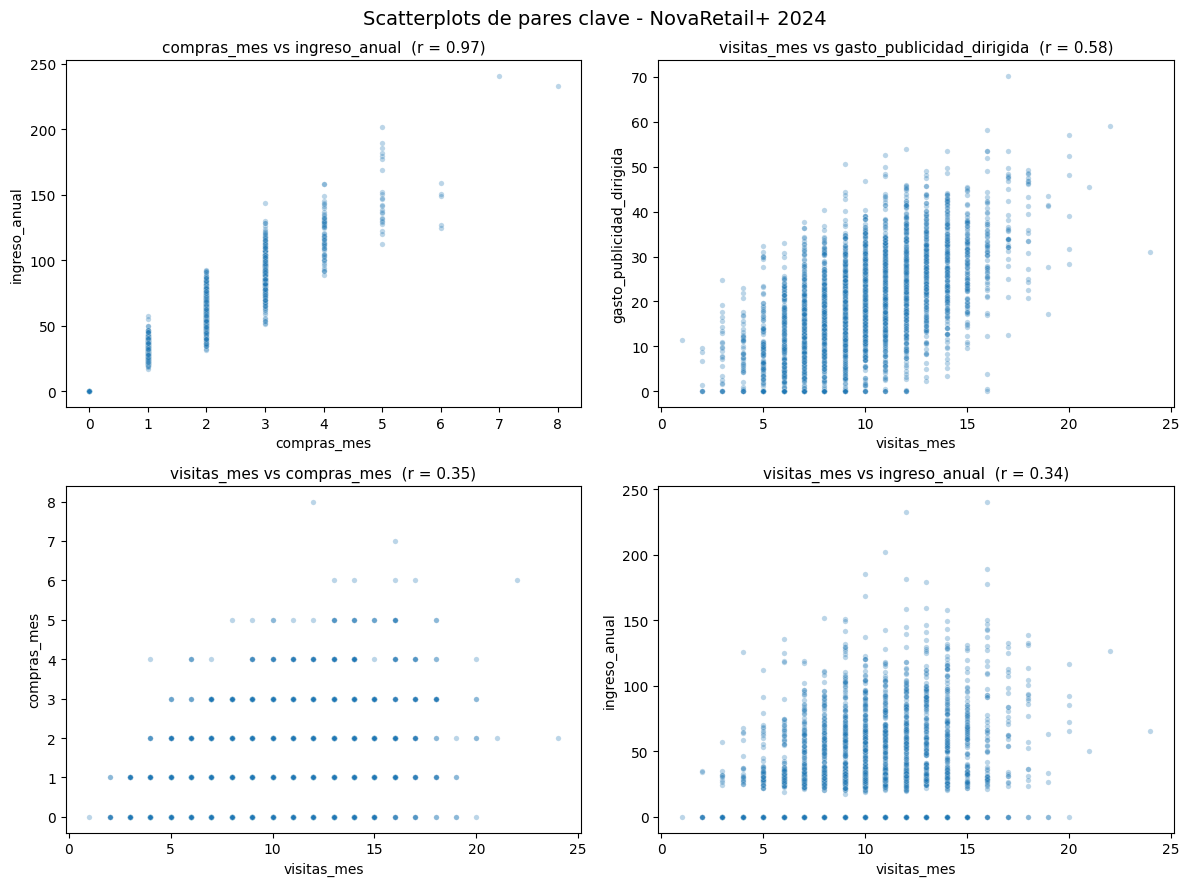

In [13]:
# Visualizar pares de variables con relaciones moderadas o fuertes
pares_clave = [
    ("compras_mes", "ingreso_anual"),                 # fuerte (0.97)
    ("visitas_mes", "gasto_publicidad_dirigida"),     # moderada (0.58)
    ("visitas_mes", "compras_mes"),                   # débil-moderada (0.35)
    ("visitas_mes", "ingreso_anual"),                 # débil-moderada (0.34)
]

muestra = df.sample(3000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (x, y) in zip(axes.flatten(), pares_clave):
    r = df[x].corr(df[y])
    sns.scatterplot(data=muestra, x=x, y=y, alpha=0.3, s=15, ax=ax)
    ax.set_title(f"{x} vs {y}  (r = {r:.2f})", fontsize=11)

fig.suptitle("Scatterplots de pares clave - NovaRetail+ 2024", fontsize=14)
plt.tight_layout()
plt.show()

✍️ **Comentario**: ✍️ Observaciones iniciales (Scatterplots)

**🛒 `compras_mes` vs `ingreso_anual` (r = 0.97)**

- **Dirección:** positiva y muy marcada; cada compra adicional eleva el ingreso de forma escalonada (aprox. 30–40 por compra).
- **Dispersión:** baja. Los puntos forman columnas verticales bien definidas, una por cada número de compras.
- **Outliers:** pocos clientes con 7–8 compras alcanzan ingresos cercanos a 240, muy por encima del resto.
- **Colinealidad:** ⚠️ **sí**. Los clientes con 0 compras tienen exactamente 0 de ingreso, lo que explica por qué al menos el 25 % no generó ingresos. Ambas variables miden prácticamente lo mismo.

**📢 `visitas_mes` vs `gasto_publicidad_dirigida` (r = 0.58)**

- **Dirección:** positiva; a más visitas, mayor tiende a ser el gasto publicitario asignado.
- **Dispersión:** alta. Con 10 visitas, por ejemplo, el gasto va desde 0 hasta más de 45.
- **Outliers:** algunos usuarios superan los 55–70 de gasto, y hay clientes sin inversión publicitaria (0) en casi todos los niveles de visitas.
- **Colinealidad:** no. La relación es moderada, no lo bastante fuerte para considerarlas redundantes.

**📱 `visitas_mes` vs `compras_mes` (r = 0.35)**

- **Dirección:** positiva pero débil; los usuarios que visitan más compran un poco más en promedio.
- **Dispersión:** alta. Hay clientes con 15–20 visitas que no realizaron ninguna compra.
- **Outliers:** casos aislados de 7–8 compras, que se separan claramente del grupo.
- **Colinealidad:** no.

**💰 `visitas_mes` vs `ingreso_anual` (r = 0.34)**

- **Dirección:** positiva y débil.
- **Dispersión:** alta, con una franja de clientes en 0 de ingreso en todos los niveles de visitas.
- **Outliers:** varios clientes superan los 200 de ingreso anual.
- **Colinealidad:** no. El patrón es muy parecido al de visitas vs compras, lo que sugiere que la relación con el ingreso **pasa a través de las compras**.

> **📌 Conclusión:** la única relación fuerte es entre compras e ingreso anual, y es casi una equivalencia más que un hallazgo. La actividad en la plataforma (visitas) y la publicidad se asocian de forma más débil y con mucha variabilidad: **visitar o recibir publicidad no garantiza comprar**, que es lo que realmente se refleja en el ingreso.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [14]:
# Calcular correlación entre variables relevantes
columnas_numericas = ["edad", "nivel_ingreso", "visitas_mes", "compras_mes",
                      "gasto_publicidad_dirigida", "satisfaccion", "ingreso_anual"]

def corr_con_objetivo(df, columnas, objetivo="ingreso_anual", metodo="pearson"):
    corr = df[columnas].corr(method=metodo)[objetivo].drop(objetivo)
    return corr.sort_values(ascending=False).round(3)

pearson = corr_con_objetivo(df, columnas_numericas, metodo="pearson")
print("📈 Correlación de Pearson con ingreso_anual:")
print(pearson)

📈 Correlación de Pearson con ingreso_anual:
compras_mes                  0.967
visitas_mes                  0.337
gasto_publicidad_dirigida    0.197
satisfaccion                 0.056
edad                         0.017
nivel_ingreso                0.017
Name: ingreso_anual, dtype: float64


In [15]:
# Calcular correlación entre variables relevantes
spearman = corr_con_objetivo(df, columnas_numericas, metodo="spearman")

comparacion = pd.DataFrame({"Pearson": pearson, "Spearman": spearman})
comparacion["Diferencia"] = (comparacion["Spearman"] - comparacion["Pearson"]).round(3)
comparacion = comparacion.sort_values("Spearman", ascending=False)

print("📊 Comparación Pearson vs Spearman con ingreso_anual:")
comparacion

📊 Comparación Pearson vs Spearman con ingreso_anual:


,Pearson,Spearman,Diferencia
compras_mes,0.967,0.967,0.000
visitas_mes,0.337,0.321,-0.016
gasto_publicidad_dirigida,0.197,0.185,-0.012
satisfaccion,0.056,0.061,0.005
nivel_ingreso,0.017,0.025,0.008
edad,0.017,0.016,-0.001


✍️ **Comentario**: ✍️ Observaciones de correlación (Pearson vs Spearman)

**🛒 `compras_mes` vs `ingreso_anual`**

- **Correlación:** Pearson 0.967 · Spearman 0.967
- **Dirección y magnitud:** positiva y **muy fuerte**; ambos métodos coinciden exactamente.
- **Colinealidad:** ⚠️ **sí** (> 0.85). El ingreso anual es prácticamente una consecuencia directa del número de compras, por lo que ambas variables aportan casi la misma información.

**📱 `visitas_mes` vs `ingreso_anual`**

- **Correlación:** Pearson 0.337 · Spearman 0.321
- **Dirección y magnitud:** positiva y **débil-moderada**; los clientes más activos tienden a generar algo más de ingreso, aunque con mucha variabilidad.
- **Colinealidad:** no.

**📢 `gasto_publicidad_dirigida` vs `ingreso_anual`**

- **Correlación:** Pearson 0.197 · Spearman 0.185
- **Dirección y magnitud:** positiva pero **débil**; la inversión publicitaria por sí sola apenas se asocia con el ingreso generado.
- **Colinealidad:** no.

**⭐ `satisfaccion`, 💼 `nivel_ingreso` y 👤 `edad` vs `ingreso_anual`**

- **Correlación:** entre 0.016 y 0.061 con ambos métodos.
- **Dirección y magnitud:** **prácticamente nula**; ninguna de estas características se relaciona con lo que el cliente aporta a la empresa.
- **Colinealidad:** no.

**🔗 Entre variables explicativas**

- `visitas_mes` vs `gasto_publicidad_dirigida` (0.58) es la relación más alta entre variables que no son el objetivo. Es moderada y queda lejos del umbral de colinealidad (0.85), así que ambas pueden analizarse por separado.

> **📌 Conclusión:** Pearson y Spearman son prácticamente iguales en todas las variables (diferencias de 0.016 como máximo). Esto indica que las relaciones son **lineales** y que, aunque `ingreso_anual` presenta sesgo y valores atípicos, **estos no distorsionan los resultados**. El ranking de asociación con el ingreso queda claro: **compras ≫ visitas > publicidad**, mientras que satisfacción, ingreso personal y edad no muestran relación.

### Punto-biserial

In [16]:
# Calcular correlación entre variables relevantes
columnas_binarias = ["miembro_premium", "abandono"]
columnas_numericas = ["ingreso_anual", "compras_mes", "visitas_mes", "gasto_publicidad_dirigida", "satisfaccion"]

def corr_point_biserial(df, col_binaria, columnas_numericas):
    resultados = []
    for col in columnas_numericas:
        coef, p_value = pointbiserialr(df[col_binaria], df[col])
        resultados.append({"variable": col, "punto_biserial": round(coef, 3), "p_value": round(p_value, 4)})
    return pd.DataFrame(resultados).set_index("variable")

for col_bin in columnas_binarias:
    print(f"🔹 Punto-biserial: {col_bin}")
    print(corr_point_biserial(df, col_bin, columnas_numericas))
    print()

# ingreso anual promedio por grupo, para interpretar la magnitud
print("💰 Ingreso anual promedio por grupo:")
for col_bin in columnas_binarias:
    print(f"\n{col_bin}")
    print(df.groupby(col_bin)["ingreso_anual"].mean().round(2))

🔹 Punto-biserial: miembro_premium
                           punto_biserial  p_value
variable                                          
ingreso_anual                       0.093   0.0000
compras_mes                         0.003   0.6744
visitas_mes                        -0.013   0.1211
gasto_publicidad_dirigida           0.003   0.7390
satisfaccion                        0.026   0.0016

🔹 Punto-biserial: abandono
                           punto_biserial  p_value
variable                                          
ingreso_anual                      -0.003   0.7295
compras_mes                         0.008   0.3099
visitas_mes                        -0.009   0.2734
gasto_publicidad_dirigida          -0.005   0.5744
satisfaccion                       -0.024   0.0035

💰 Ingreso anual promedio por grupo:

miembro_premium
miembro_premium
0    35.30
1    44.58
Name: ingreso_anual, dtype: float64

abandono
abandono
0    36.64
1    36.36
Name: ingreso_anual, dtype: float64


✍️ **Comentario**: ✍️ Observaciones Punto-biserial

**💎 `miembro_premium` vs `ingreso_anual`**

- **Relación:** positiva y de magnitud **baja** (r = 0.093), pero estadísticamente significativa (p < 0.001).
- Aunque el coeficiente es pequeño, la diferencia en términos de negocio es notable: los clientes premium generan en promedio **44.58** frente a **35.30** de los no premium, cerca de un **26 % más de ingreso**.
- Lo interesante es que ser premium **no se asocia con comprar más** (r = 0.003), **visitar más** (r = -0.013) ni recibir más publicidad (r = 0.003). Esto sugiere que el mayor ingreso de los premium no viene de una mayor frecuencia de compra, sino posiblemente de un **mayor valor por compra** o del propio pago de la suscripción, una hipótesis que habría que validar.

**🚪 `abandono` vs `ingreso_anual`**

- **Relación:** prácticamente **nula** (r = -0.003) y no significativa (p = 0.73).
- Los clientes que abandonaron generaban casi el mismo ingreso que los que se quedaron (**36.36** frente a **36.64**).
- El abandono tampoco se relaciona con compras, visitas ni publicidad. La única asociación significativa es con `satisfaccion` (r = -0.024), pero es tan débil que **no tiene relevancia práctica**.

> **📌 Conclusión:** la membresía premium es la única variable binaria asociada con el ingreso, y su efecto en dinero es relevante aunque el coeficiente sea bajo. El abandono, en cambio, **no se explica por ninguna de las variables analizadas**: los clientes que se van son tan valiosos como los que se quedan, lo que significa que cada abandono representa una pérdida real de ingreso y que sus causas deben buscarse en factores que este dataset no incluye.
>
> ⚠️ Con 15,000 registros, incluso relaciones muy pequeñas pueden resultar estadísticamente significativas; por eso, además del p-value, se evaluó la **magnitud real** de cada relación.

### V de Cramér

In [17]:
# Función para calcular V de Cramér
def cramers_v(df, col_1, col_2):
    # tabla de contingencia
    tabla = pd.crosstab(df[col_1], df[col_2])

    # calcular chi-cuadrado
    chi2, p_value, _, _ = chi2_contingency(tabla)

    # calcular coeficiente V de Cramér
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

    return round(v, 3), round(p_value, 4)

In [18]:
# Aplicar V de Cramér en variables relevantes
pares_categoricos = [
    ("tipo_dispositivo", "region"),
    ("tipo_dispositivo", "miembro_premium"),
    ("tipo_dispositivo", "abandono"),
    ("region", "miembro_premium"),
    ("region", "abandono"),
]

resultados = []
for col_1, col_2 in pares_categoricos:
    v, p = cramers_v(df, col_1, col_2)
    resultados.append({"par": f"{col_1} vs {col_2}", "V_cramer": v, "p_value": p})

print("🔗 V de Cramér entre variables categóricas:")
print(pd.DataFrame(resultados).set_index("par"))
print()

# ingreso anual promedio por categoría, para conectar con la variable objetivo
for col in ["tipo_dispositivo", "region"]:
    print(f"💰 Ingreso anual promedio por {col}:")
    print(df.groupby(col)["ingreso_anual"].mean().round(2).sort_values(ascending=False))
    print()

🔗 V de Cramér entre variables categóricas:
                                     V_cramer  p_value
par                                                   
tipo_dispositivo vs region              0.012   0.5965
tipo_dispositivo vs miembro_premium     0.020   0.0540
tipo_dispositivo vs abandono            0.007   0.6746
region vs miembro_premium               0.013   0.4989
region vs abandono                      0.015   0.3117

💰 Ingreso anual promedio por tipo_dispositivo:
tipo_dispositivo
tablet        37.07
móvil         36.59
escritorio    36.42
Name: ingreso_anual, dtype: float64

💰 Ingreso anual promedio por region:
region
sur      37.10
este     36.89
norte    36.71
oeste    35.72
Name: ingreso_anual, dtype: float64



✍️ **Comentario**: ✍️ Observaciones V de Cramér

**🔗 Asociación entre variables categóricas**

| Par de variables | V de Cramér | p-value | Asociación |
|---|---|---|---|
| 📱 `tipo_dispositivo` vs 🗺️ `region` | 0.012 | 0.597 | Nula |
| 📱 `tipo_dispositivo` vs 💎 `miembro_premium` | 0.020 | 0.054 | Nula |
| 📱 `tipo_dispositivo` vs 🚪 `abandono` | 0.007 | 0.675 | Nula |
| 🗺️ `region` vs 💎 `miembro_premium` | 0.013 | 0.499 | Nula |
| 🗺️ `region` vs 🚪 `abandono` | 0.015 | 0.312 | Nula |

- Todos los valores de V están **muy por debajo de 0.1** y ninguno es estadísticamente significativo (p > 0.05). El caso más cercano, dispositivo vs premium (p = 0.054), tiene un coeficiente tan bajo (0.020) que no representa una diferencia real.
- El uso de cada dispositivo es prácticamente igual en todas las regiones, y **ni la región ni el dispositivo se asocian con ser premium o con abandonar** la plataforma.

**💰 Relación con `ingreso_anual`**

- **Por dispositivo:** el ingreso promedio va de **36.42** (escritorio) a **37.07** (tablet), una diferencia de apenas 0.65.
- **Por región:** va de **35.72** (oeste) a **37.10** (sur), una diferencia de 1.38.
- En ambos casos, las diferencias son mínimas frente a la variabilidad del ingreso (desviación estándar ≈ 34.5), por lo que **no son relevantes para el negocio**.

> **📌 Conclusión:** el dispositivo y la región **no influyen en el comportamiento ni en el valor de los clientes**: un usuario de tablet en el sur se comporta y genera prácticamente lo mismo que uno de escritorio en el oeste. Esto tiene dos implicaciones:
>
> 1. Las estrategias de crecimiento y retención **pueden aplicarse de forma general**, sin necesidad de segmentar por dispositivo o región.
> 2. Al no existir asociación entre estas variables, **no actúan como factores de confusión**, lo que reduce el riesgo de correlaciones engañosas (como la paradoja de Simpson) en los resultados anteriores.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

✍️ **Hallazgos**: 🔎 Hallazgos

---

#### 🛒 Hallazgo 1 — La frecuencia de compra es el principal factor asociado al ingreso

- **Evidencia visual:** heatmap (3.1) y scatterplot `compras_mes` vs `ingreso_anual` (3.3), donde el ingreso sube de forma escalonada con cada compra.
- **Evidencia numérica:** Pearson = 0.967 · Spearman = 0.967. Los clientes con 0 compras tienen exactamente 0 de ingreso.
- **Interpretación:** el ingreso anual de un cliente se asocia casi por completo con cuántas compras realiza. Ambas variables presentan **colinealidad** y, en la práctica, miden lo mismo.
- **No podemos afirmar:** que esta relación sea un hallazgo por sí misma; es esperable que más compras impliquen más ingreso. Tampoco sabemos qué impulsa a un cliente a comprar más.
- **Implicación de negocio:** la palanca principal para aumentar el ingreso es **incrementar la frecuencia de compra**. Las iniciativas de crecimiento deberían medirse por su impacto en compras, no solo en tráfico.

---

#### 📱 Hallazgo 2 — Visitar más la plataforma no garantiza comprar

- **Evidencia visual:** scatterplots `visitas_mes` vs `compras_mes` y `visitas_mes` vs `ingreso_anual` (3.3), con alta dispersión y clientes sin compras incluso con 15–20 visitas.
- **Evidencia numérica:** visitas vs ingreso = 0.337 · visitas vs compras = 0.35.
- **Interpretación:** los clientes más activos tienden a comprar y generar algo más de ingreso, pero la relación es débil-moderada y con mucha variabilidad.
- **No podemos afirmar:** que aumentar las visitas aumente el ingreso; el tráfico por sí solo no se traduce de forma consistente en compras.
- **Implicación de negocio:** existe una **brecha de conversión**. Más que atraer visitas, conviene optimizar la experiencia que convierte una visita en compra (recomendaciones, proceso de pago, ofertas personalizadas).

---

#### 📢 Hallazgo 3 — La publicidad dirigida se asocia más con visitas que con ingreso

- **Evidencia visual:** heatmap (3.1) y scatterplot `visitas_mes` vs `gasto_publicidad_dirigida` (3.3).
- **Evidencia numérica:** publicidad vs visitas = 0.58 · publicidad vs ingreso = 0.197 · publicidad vs compras = 0.21.
- **Interpretación:** los usuarios con más inversión publicitaria son también los que más visitan, pero esa relación se debilita al llegar a las compras y al ingreso.
- **No podemos afirmar:** que la publicidad genere visitas; también es posible que se **asigne a los usuarios que ya eran más activos** (causalidad inversa). Tampoco podemos afirmar que aumentar la inversión aumente el ingreso.
- **Implicación de negocio:** antes de incrementar el presupuesto publicitario, se recomienda un **experimento A/B** que mida su efecto real sobre compras e ingreso, y revisar el criterio con el que se asigna el gasto.

---

#### 💎 Hallazgo 4 — Los clientes premium generan más ingreso sin comprar más seguido

- **Evidencia numérica:** punto-biserial con `ingreso_anual` = 0.093 (p < 0.001). Ingreso promedio: **44.58** premium vs **35.30** no premium (≈ 26 % más). Sin relación con compras (0.003) ni visitas (-0.013).
- **Interpretación:** ser premium se asocia con un mayor ingreso, pero no con una mayor frecuencia de compra ni de visitas.
- **No podemos afirmar:** que la membresía premium haga que los clientes gasten más; podría ser que los clientes que ya gastaban más sean quienes eligen suscribirse. Tampoco sabemos si la diferencia proviene de un mayor valor por compra o del propio cobro de la suscripción.
- **Implicación de negocio:** el programa premium es un **segmento valioso** que vale la pena entender mejor. Se recomienda analizar el ticket promedio por compra y evaluar, mediante un experimento, si promover la membresía aumenta el ingreso por cliente.

---

#### 🚪 Hallazgo 5 — El abandono no se explica con las variables disponibles

- **Evidencia numérica:** punto-biserial con `ingreso_anual` = -0.003 (p = 0.73). Ingreso promedio: **36.36** (abandonó) vs **36.64** (se quedó). Sin relación con compras, visitas, publicidad, dispositivo ni región (V de Cramér < 0.02).
- **Interpretación:** los clientes que abandonan no se distinguen de los que se quedan en ninguna de las variables analizadas, y son igual de valiosos para la empresa.
- **No podemos afirmar:** por qué abandonan los clientes; las causas no están representadas en este dataset.
- **Implicación de negocio:** cada abandono implica perder un cliente de valor promedio. El equipo de retención debería **recolectar nueva información** (encuestas de salida, historial de soporte, precios, tiempos de entrega) para identificar las causas reales.

---

#### ⭐ Hallazgo 6 — Satisfacción, perfil del cliente, dispositivo y región no se asocian con el ingreso

- **Evidencia visual:** heatmap (3.1), donde estas variables aparecen en tonos neutros.
- **Evidencia numérica:** `satisfaccion` = 0.056 · `nivel_ingreso` = 0.017 · `edad` = 0.017. Ingreso promedio por dispositivo entre 36.42 y 37.07, y por región entre 35.72 y 37.10.
- **Interpretación:** el ingreso que genera un cliente no varía según su edad, su ingreso personal, su satisfacción, el dispositivo que usa o la región donde vive.
- **No podemos afirmar:** que la satisfacción no importe; podría influir en aspectos no medidos aquí (recomendaciones, reseñas) o que la escala actual no capture bien la experiencia del cliente.
- **Implicación de negocio:** **segmentar por dispositivo, región, edad o ingreso personal no aporta valor** para estrategias de ingreso, así que las iniciativas pueden aplicarse de forma general. También conviene revisar si la encuesta de satisfacción realmente refleja la experiencia de compra.

### Hallazgo 1 — 

### 5.1. Hallazgo 1 — 🛒 La frecuencia de compra es el principal factor asociado al ingreso

**Evidencia visual:** heatmap (3.1) y scatterplot `compras_mes` vs `ingreso_anual` (3.3), donde el ingreso sube de forma escalonada con cada compra.  
**Evidencia numérica:** Pearson = 0.967 · Spearman = 0.967. Los clientes con 0 compras tienen exactamente 0 de ingreso.

**Interpretación**  
El ingreso anual de un cliente se asocia casi por completo con el número de compras que realiza. Ambas variables presentan **colinealidad** y, en la práctica, miden lo mismo.

**No podemos afirmar**  
Que esta relación sea un hallazgo en sí misma, ya que es esperable que más compras impliquen más ingreso. Tampoco sabemos qué impulsa a un cliente a comprar con mayor frecuencia.

**Implicación de negocio**  
La palanca principal para aumentar el ingreso es **incrementar la frecuencia de compra**. Las iniciativas de crecimiento deberían evaluarse por su impacto en compras, no solo en tráfico.

### Hallazgo 2 —

### 5.2. Hallazgo 2 — 📱 Visitar más la plataforma no garantiza comprar

**Evidencia visual:** scatterplots `visitas_mes` vs `compras_mes` y `visitas_mes` vs `ingreso_anual` (3.3), con alta dispersión y clientes sin compras incluso con 15–20 visitas.  
**Evidencia numérica:** visitas vs ingreso = 0.337 · visitas vs compras = 0.35.

**Interpretación**  
Los clientes más activos tienden a comprar y generar algo más de ingreso, pero la relación es débil-moderada y con mucha variabilidad.

**No podemos afirmar**  
Que aumentar las visitas aumente el ingreso; el tráfico por sí solo no se traduce de forma consistente en compras.

**Implicación de negocio**  
Existe una **brecha de conversión**. Más que atraer visitas, conviene optimizar lo que convierte una visita en compra: recomendaciones, proceso de pago y ofertas personalizadas.

### 5.3. Hallazgo 3 — 📢 La publicidad dirigida se asocia más con visitas que con ingreso

**Evidencia visual:** heatmap (3.1) y scatterplot `visitas_mes` vs `gasto_publicidad_dirigida` (3.3).  
**Evidencia numérica:** publicidad vs visitas = 0.58 · publicidad vs compras = 0.21 · publicidad vs ingreso = 0.197.

**Interpretación**  
Los usuarios con mayor inversión publicitaria son también los que más visitan la plataforma, pero esa relación se debilita al llegar a las compras y al ingreso.

**No podemos afirmar**  
Que la publicidad genere visitas; también es posible que se **asigne a los usuarios que ya eran más activos** (causalidad inversa). Tampoco que aumentar la inversión aumente el ingreso.

**Implicación de negocio**  
Antes de incrementar el presupuesto publicitario, se recomienda un **experimento A/B** que mida su efecto real sobre compras e ingreso, y revisar el criterio con el que se asigna el gasto.

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: ### ⚠️ Limitaciones

- **Análisis correlacional, no causal:** los resultados muestran qué variables se mueven juntas, pero no permiten afirmar que una provoque cambios en la otra.
- **Diferencia en la escala temporal:** `visitas_mes` y `compras_mes` son métricas mensuales, mientras que `ingreso_anual` es anual. Comparar ambas supone que el comportamiento de un mes representa al de todo el año, lo cual podría no cumplirse en temporadas altas o bajas.
- **Colinealidad entre compras e ingreso:** su correlación casi perfecta (0.97) indica que miden prácticamente lo mismo, por lo que el análisis no permite identificar qué factores *previos* impulsan las compras.
- **Variables faltantes:** el dataset no incluye información clave como el ticket promedio por compra, la antigüedad del cliente, las categorías de productos, el canal de adquisición ni los motivos de abandono.
- **Asignación desconocida de la publicidad:** no sabemos con qué criterio se distribuye el gasto publicitario, lo que abre la posibilidad de causalidad inversa (que se invierta más en quienes ya eran activos).
- **Satisfacción autorreportada:** la calificación de 1 a 5 podría no reflejar con precisión la experiencia real del cliente.
- **Alcance de los métodos:** Pearson y Spearman solo detectan relaciones lineales o monótonas entre pares de variables; no capturan interacciones entre varias variables a la vez.
- **Tamaño de la muestra:** con 15,000 registros, incluso relaciones muy pequeñas resultan estadísticamente significativas, por lo que la interpretación se basó en la **magnitud** y no solo en el p-value.

### 🚀 Próximos pasos

1. **Experimento A/B de publicidad:** medir si la inversión publicitaria realmente incrementa compras e ingreso, asignándola de forma aleatoria.
2. **Analizar el ticket promedio de los clientes premium:** entender si su mayor ingreso proviene de compras de mayor valor o del costo de la suscripción.
3. **Estudiar el embudo de conversión:** identificar en qué punto los usuarios que visitan la plataforma dejan de comprar.
4. **Recolectar información sobre el abandono:** encuestas de salida, historial de soporte, precios y tiempos de entrega, para construir más adelante un modelo predictivo de abandono.
5. **Incorporar datos en el tiempo:** contar con información mensual de cada cliente durante todo el año para resolver la diferencia de escalas y detectar patrones estacionales.
6. **Análisis multivariado:** aplicar modelos de regresión que evalúen varias variables al mismo tiempo y controlen posibles factores de confusión.

### 6.2. ⚠️ Limitaciones

- **Correlación ≠ causalidad:** el análisis muestra qué variables se mueven juntas, pero no permite afirmar que una provoque cambios en la otra.
- **Diferencia de escala temporal:** `visitas_mes` y `compras_mes` son mensuales, mientras que `ingreso_anual` es anual. Se asume que un mes representa el comportamiento de todo el año, lo que podría no cumplirse en temporadas altas o bajas.
- **Colinealidad entre compras e ingreso (0.97):** ambas variables miden prácticamente lo mismo, por lo que el análisis no permite identificar qué factores *previos* impulsan las compras.
- **Variables faltantes:** el dataset no incluye el ticket promedio por compra, la antigüedad del cliente, las categorías de producto, el canal de adquisición ni los motivos de abandono.
- **Asignación desconocida de la publicidad:** no sabemos con qué criterio se distribuye el gasto publicitario, lo que deja abierta la posibilidad de causalidad inversa.
- **Satisfacción autorreportada:** la escala de 1 a 5 podría no reflejar con precisión la experiencia real de compra.
- **Alcance de los métodos:** las correlaciones evalúan pares de variables y no capturan interacciones entre varias variables a la vez.
- **Significancia vs. relevancia:** con 15,000 registros, incluso relaciones muy pequeñas resultan significativas; por eso la interpretación se basó en la **magnitud** de cada relación y no solo en el p-value.

### 6.3. 🚀 Próximos pasos

**Paso 1 — Probar segmentación adicional**

Como el dispositivo y la región no mostraron diferencias, la segmentación debería basarse en el **comportamiento** del cliente:

- **Premium vs. no premium:** comparar el ticket promedio por compra para entender de dónde proviene su 26 % de ingreso adicional.
- **Usuarios activos sin compras:** aislar a los clientes con muchas visitas y 0 compras para estudiar la brecha de conversión.
- **Niveles de gasto publicitario:** comparar compras e ingreso entre usuarios con inversión baja, media y alta.

**Paso 2 — Validar relaciones mediante experimentos**

- **Experimento A/B de publicidad:** asignar el gasto de forma aleatoria para medir su efecto real sobre compras e ingreso.
- **Experimento de promoción premium:** ofrecer la membresía a un grupo aleatorio y evaluar si aumenta el ingreso por cliente.

**Paso 3 — Ampliar y enriquecer los datos**

- **Información sobre abandono:** encuestas de salida, historial de soporte, precios y tiempos de entrega, para construir un modelo predictivo de abandono.
- **Datos en el tiempo:** registrar la actividad mensual de cada cliente durante todo el año para resolver la diferencia de escalas y detectar estacionalidad.
- **Análisis multivariado:** aplicar modelos de regresión que evalúen varias variables a la vez y controlen posibles factores de confusión.

In [19]:
# Guardar el dataset limpio
ruta_limpia = "novaretail_comportamiento_clientes_2024_clean.csv"
df.to_csv(ruta_limpia, index=False)

# Verificar que el archivo se guardó correctamente
df_clean = pd.read_csv(ruta_limpia)
print(f"✅ Dataset limpio guardado como: {ruta_limpia}")
print(f"📏 Dimensiones: {df_clean.shape[0]:,} filas × {df_clean.shape[1]} columnas")
print(f"🔢 Tipo de 'edad': {df_clean['edad'].dtype}")
print(f"❓ Valores nulos totales: {df_clean.isna().sum().sum()}")

✅ Dataset limpio guardado como: novaretail_comportamiento_clientes_2024_clean.csv
📏 Dimensiones: 15,000 filas × 12 columnas
🔢 Tipo de 'edad': int64
❓ Valores nulos totales: 0
